# Hypothetical extreme planets: the $A_B$ bias at the Roche limit

Where the $a/R_\star$ axis of the bias maps physically ends, and how large the bias from neglecting hyperillumination gets there. The Roche limit is a fixed orbital period for a given planet composition, so it moves in $a/R_\star$ with the host's density.

In [1]:
import numpy as np
import warnings
import pandas as pd
import os
import contextlib, io
import matplotlib.pyplot as plt
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.defaults import (DEFAULT_A, DEFAULT_A_B, DEFAULT_MAP_RP_RS, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U,
                                 DEFAULT_U_BOL)
from hyperphase.plotting.irradiance import plot_model_insolmaps
from hyperphase.model import ConstantBandAlbedo, FittingConfig
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.roche import G_CGS, rho_star, ROCHE_CASES, roche_period_h, roche_proximity, ROCHE_R_P, rocky_mean_density
from hyperphase.bias.maps import (bias_map_grid, map_grid, moved_planet, print_allowed_extremes, reference_planet, roche_allowed_masks,
                                  roche_frontier_a_rs, roche_periods)
from hyperphase.bias.tables import planet_bias_table, planet_false_F_table, railed_names
from hyperphase.plotting.bias import plot_planet_false_F_bars, plot_planet_retrievals
from hyperphase.plotting.maps import plot_bias_maps
from hyperphase.plotting.style import set_plot_style
from hyperphase.targets import hi_planets_by_name, planet_archive_value, ROCKY_MAX_RADE
from hyperphase.noise import rms_1min_pandexo_sample
from hyperphase.paper import PAPER_PLANETS
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor", module="joblib")   # loky replaces a worker whose memory grew (SPIDERMAN's allocator) and warns; its jobs are rerun, the results are unaffected

# Exoplanet Archive (planet overlay on the map, the shortest-period planets)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'inputs', 'exoplanet_archive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Reference geometry of the map (the same values as 03_bias_maps.ipynb): every cell inherits it for whatever is not swept
incl_ref  = 90.                 # [deg] central transit, so every cell occults
rp_rs_ref = DEFAULT_MAP_RP_RS   # Rp/Rs held fixed
ref = reference_planet(rp_rs=rp_rs_ref, T_eff=4000., incl=incl_ref)   # a/Rs and T_eff are swept by the map
anchors = hi_planets_by_name(["TOI-2431 b", "K2-141 b"])              # the reference planets, moved to their Roche limit in section 3

u, u_bol = DEFAULT_U, DEFAULT_U_BOL       # transit and irradiance limb darkening
A_B_true = DEFAULT_A_B                    # Bond albedo of the truth, the same for every map cell and planet
A_model = ConstantBandAlbedo(DEFAULT_A)   # band albedo A of the reflected light, independent of A_B

instrument = "MIRI/LRS"   # or e.g. "JWST_NIRSpec.G395H_NRS1", "MIRI/F1280W"
filter_path = filter_loc(instrument)
l1, l2 = filter_lambda(instrument)
n_bins = DEFAULT_N_BINS       # bins per orbit
n_orbits = DEFAULT_N_ORBITS   # orbits observed; enters only the Fisher sigmas and chi^2 (the biases are noise-independent)

# sigma_1min is a placeholder for the map (the bias does not depend on the noise scale); the per-planet fits use the anchors' PandExo noise
cfg = FittingConfig(planet=ref, filter_path=filter_path,
                    l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins,
                    reflected=True, u_bol=u_bol, u=u)
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)     # n_layers is left to the per-model default of pcurve_params

sigma_anchors = rms_1min_pandexo_sample(list(anchors), instrument)   # from the PandExo cache where possible
print("sigma_1min [" + instrument + "]: " + ", ".join(f"{nm} {s:.1f} ppm" for nm, s in sigma_anchors.items()))

set_plot_style()
geom = rf"$A_B$ = {A_B_true:.2f}, $i$ = {incl_ref:g}°"   # for the figure titles

sigma_1min [MIRI/LRS]: TOI-2431 b 62.9 ppm, K2-141 b 99.2 ppm


## 1. The Roche limit

Inside the Roche limit the stellar tide disrupts the planet. For a uniform fluid body on a circular, synchronous orbit $a_{\rm R}/R_\star = 2.44\,(\rho_\star/\rho_p)^{1/3}$, a period that depends on the planet alone; a centrally condensed planet survives closer in (Rappaport et al. 2013, eqs. 1 and 5; `roche_period_h`):
$$P_{\rm R} = 12.6\,{\rm h}\,(\rho_p/{\rm g\,cm^{-3}})^{-1/2}\,(\rho_0/\rho_p)^{-0.16},$$
with $\rho_0/\rho_p$ the central over the mean density. Two compositions of a 1.5 $R_\oplus$ planet (`roche.ROCHE_CASES`, mean densities from Fortney et al. 2007): *Earth-like* (33 % iron, $\rho_0/\rho_p$ = 2.37) and *iron-rich* (70 % iron, the most mantle stripping leaves, Marcus et al. 2010; $\rho_0/\rho_p$ = 2.5), the innermost limit of any rocky planet of this size. On the maps $a_{\rm R}/R_\star = (G\rho_\star P_{\rm R}^2/3\pi)^{1/3}$ with the main-sequence $\rho_\star(T_{\rm eff})$ of Pecaut & Mamajek (2013); a planet's own distance from its limit, $a/a_{\rm R} = (P/P_{\rm R})^{2/3}$, needs no stellar density. The cell also prints the limits for larger planets and the contact limit $a/R_\star = 1 + R_p/R_\star$.

In [3]:
periods = roche_periods()   # {label: P_R [h]} of ROCHE_CASES at ROCHE_R_P: the lines on every (a/R*, T_eff) map
T_show = (3000., 3500., 4000., 5000., 6000.)   # [K] main-sequence hosts at which the limit is shown in a/R*
rows = []
for (comp, (fe, q)), (lab, P_R) in zip(ROCHE_CASES.items(), periods.items()):
    rho_p = rocky_mean_density(ROCHE_R_P, fe)
    rows.append({"composition": lab, "iron fraction": fe, "rho_mean [g/cm^3]": rho_p, "rho_0/rho_mean": q, "P_R [h]": P_R, "P_R uniform body [h]": float(roche_period_h(rho_p)),
                 **{f"a_R/R* ({T:.0f} K)": float(roche_frontier_a_rs(T, P_R)) for T in T_show}})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print("\nP_R [h] against the planet radius (compression):")
for R in (1.0, ROCHE_R_P, ROCKY_MAX_RADE):
    print(f"  R_p = {R:g} R_E: " + ",  ".join(f"{lab.split(',')[0]} {P:.2f}" for lab, P in roche_periods(R_p=R).items()))
print(f"contact limit at the map's Rp/Rs: a/Rs = {1 + rp_rs_ref:.3f}")

                        composition  iron fraction  rho_mean [g/cm^3]  rho_0/rho_mean  P_R [h]  P_R uniform body [h]  a_R/R* (3000 K)  a_R/R* (3500 K)  a_R/R* (4000 K)  a_R/R* (5000 K)  a_R/R* (6000 K)
         Earth-like, 1.5 $R_\oplus$           0.33               7.65            2.37     3.96                  4.55             3.75              2.2             1.75             1.52             1.14
iron-rich (70 % Fe), 1.5 $R_\oplus$            0.7               13.4             2.5     2.96                  3.43             3.09             1.81             1.45             1.26            0.937

P_R [h] against the planet radius (compression):
  R_p = 1 R_E: Earth-like 4.68,  iron-rich (70 % Fe) 3.71
  R_p = 1.5 R_E: Earth-like 3.96,  iron-rich (70 % Fe) 2.96
  R_p = 1.7 R_E: Earth-like 3.66,  iron-rich (70 % Fe) 2.69
contact limit at the map's Rp/Rs: a/Rs = 1.016


### 1.1 Check against the known planets

The paper planets and the shortest-period rocky planets of the archive: `a/a_R` for both compositions and for an Earth-like planet of the planet's own radius, the host's transit density over the main-sequence value, and $a/R_\star$ relative to the Earth-like line. A planet inside its own-radius Earth-like limit must be iron-rich (as Rappaport et al. 2013 conclude for KOI-1843.03); one whose map position and `a/a_R` disagree has a host off the main sequence.

In [4]:
P_R_earth, P_R_iron = periods.values()   # in ROCHE_CASES order: Earth-like, iron-rich
earth_case = {"Earth-like": ROCHE_CASES["Earth-like"]}
arch = pd.read_csv(AGG).drop_duplicates("pl_name")
shortest = arch[arch.pl_rade < ROCKY_MAX_RADE].nsmallest(6, "pl_orbper")   # the observed edge in period
check = {**hi_planets_by_name(PAPER_PLANETS), **hi_planets_by_name(list(shortest.pl_name))}

rows = []
for nm, pl in check.items():
    P_h, a_rs = 24. * pl.period, pl.R / pl.r2
    R_p = planet_archive_value(AGG, nm, "pl_rade")
    P_R_own = next(iter(roche_periods(earth_case, R_p=R_p).values())) if np.isfinite(R_p) else np.nan
    rho_tr = 3. * np.pi * a_rs ** 3 / (G_CGS * (86400. * pl.period) ** 2)
    rows.append({"name": nm, "P [h]": P_h, "R_p [R_E]": R_p, "a/R*": a_rs, "T_eff": pl.T2_eff,
                 "a/a_R Earth-like": float(roche_proximity(P_h, P_R_earth)), "a/a_R iron-rich": float(roche_proximity(P_h, P_R_iron)),
                 "a/a_R Earth-like, own R_p": float(roche_proximity(P_h, P_R_own)),
                 "rho* transit / MS": rho_tr / float(rho_star(pl.T2_eff)), "a/R* - Earth-like line": a_rs - float(roche_frontier_a_rs(pl.T2_eff, P_R_earth))})
tab_roche = pd.DataFrame(rows).sort_values("P [h]")
print(tab_roche.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print("\ninside the iron-rich limit: " + (", ".join(tab_roche.loc[tab_roche["a/a_R iron-rich"] < 1, "name"]) or "none"))
print("inside the Earth-like limit at their own radius (must be iron-rich): " + (", ".join(tab_roche.loc[tab_roche["a/a_R Earth-like, own R_p"] < 1, "name"]) or "none"))
print("map position and a/a_R disagree (left of the Earth-like line, but outside the Earth-like limit at R_p = ROCHE_R_P): "
      + (", ".join(tab_roche.loc[(tab_roche["a/R* - Earth-like line"] < 0) & (tab_roche["a/a_R Earth-like"] >= 1), "name"]) or "none"))

       name  P [h]  R_p [R_E]  a/R*    T_eff  a/a_R Earth-like  a/a_R iron-rich  a/a_R Earth-like, own R_p  rho* transit / MS  a/R* - Earth-like line
KOI-1843.03   4.25      0.602   1.9 3.58e+03              1.05             1.27                      0.894              0.634                  -0.212
   K2-137 b   4.31       0.64   4.3  3.7e+03              1.06             1.28                      0.905                8.8                    2.33
 TOI-2431 b   5.38       1.51  2.08 4.11e+03              1.23             1.49                       1.23              0.943                    0.35
 TOI-6255 b   5.72       1.08   3.1 3.42e+03              1.28             1.55                       1.16              0.884                    0.57
 TOI-6324 b    6.7       1.03  4.29 3.25e+03              1.42             1.72                       1.28                1.3                    1.52
   K2-141 b   6.73       1.51  2.29  4.6e+03              1.42             1.73                     

## 2. The Roche frontier on the $(a/R_\star, T_{\rm eff})$ bias map

The $A_B$-only bias map of `03_bias_maps.ipynb` §1.1 (same grid), with both Roche limits; `print_allowed_extremes` gives the largest bias outside each limit. The frontier runs diagonally: the strongly biased corner lies inside the limit for M dwarfs and outside it for F and G stars.

non-railed cells: 135 of 135;  Delta A_B in [-0.926, -0.009] = [-462.8, -4.5] % of A_B
fitted A_B < 0 in 25 of 135 cells;  railed: 0


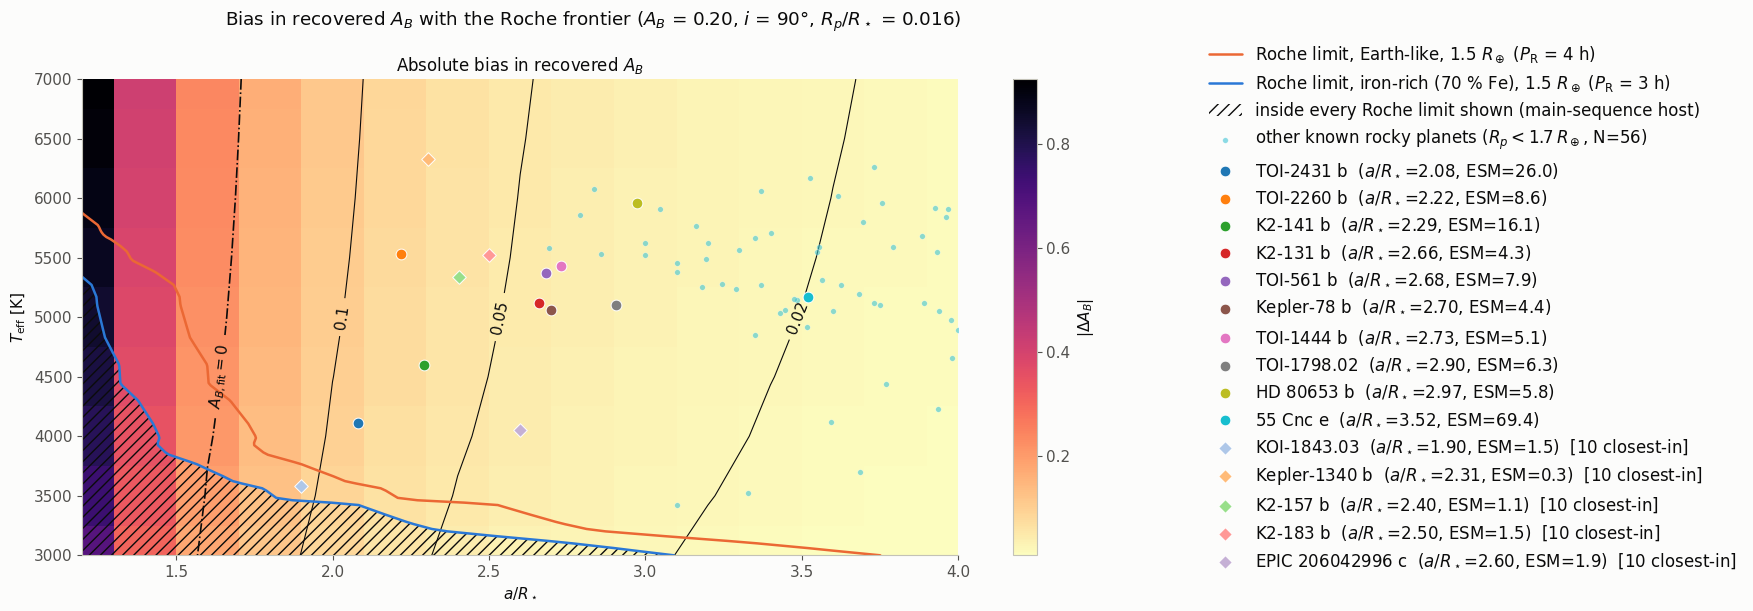

non-railed cells: 135 of 135;  largest |Delta A_B| on the whole box: 0.926
  beyond the Roche limit, Earth-like, 1.5 R_E (P_R = 3.96 h): 108 cells allowed, largest |Delta A_B| = 0.926 (462.8 % of A_B) at a/Rs = 1.20, T_eff = 7000 K
  beyond the Roche limit, iron-rich (70 % Fe), 1.5 R_E (P_R = 2.96 h): 117 cells allowed, largest |Delta A_B| = 0.926 (462.8 % of A_B) at a/Rs = 1.20, T_eff = 7000 K


In [5]:
a_rs_grid_B = map_grid(1.2, 4.0, 15)
T_eff_grid_B = map_grid(3000., 7000., 9)
bias_map_B = bias_map_grid(cfg, A_B_true, a_rs_grid_B, T_eff_grid_B, "T_s", **kw)   # A_B-only fit, cells in parallel, noise-independent
fig, axs = plot_bias_maps(a_rs_grid_B, T_eff_grid_B, bias_map_B, A_B_true, AGG, "st_teff", r"$T_{\rm eff}$ [K]", rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, planets=PAPER_PLANETS,
               roche=periods,
               title=rf"Bias in recovered $A_B$ with the Roche frontier ({geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
plt.show()
print_allowed_extremes(a_rs_grid_B, T_eff_grid_B, bias_map_B, A_B_true, roche_allowed_masks(a_rs_grid_B, T_eff_grid_B, periods), periods)

## 3. Edge cases: the reference planets at their Roche limit

Each anchor moved to the Roche period of each composition (`moved_planet`), keeping its star, $R_p/R_\star$, inclination and PandExo noise; Kepler III at the host's density sets the new $a/R_\star$, so the impact parameter shrinks. Physically allowed, but not observed.

In [6]:
edge, sigma_case = {}, {}
for nm, pl in anchors.items():
    edge[nm], sigma_case[nm] = pl, sigma_anchors[nm]
    for comp, P_R in zip(ROCHE_CASES, periods.values()):
        e = moved_planet(pl, P_R, name=f"{nm} at Roche ({comp.split(' (')[0]})")   # e.g. "TOI-2431 b at Roche (iron-rich)"
        edge[e.name], sigma_case[e.name] = e, sigma_anchors[nm]
for e in edge.values():
    a_rs = e.R / e.r2
    print(f"{e.name}: P = {24 * e.period:.2f} h, a/Rs = {a_rs:.3f}, b = {a_rs * np.cos(np.radians(e.incl)):.2f}, T_eff = {e.T2_eff:.0f} K, {100 * e.fraction_illuminated():.1f} % illuminated")

TOI-2431 b: P = 5.38 h, a/Rs = 2.080, b = 0.57, T_eff = 4109 K, 73.5 % illuminated
TOI-2431 b at Roche (Earth-like): P = 3.96 h, a/Rs = 1.696, b = 0.47, T_eff = 4109 K, 78.9 % illuminated
TOI-2431 b at Roche (iron-rich): P = 2.96 h, a/Rs = 1.398, b = 0.39, T_eff = 4109 K, 85.0 % illuminated
K2-141 b: P = 6.73 h, a/Rs = 2.292, b = 0.15, T_eff = 4599 K, 71.4 % illuminated
K2-141 b at Roche (Earth-like): P = 3.96 h, a/Rs = 1.610, b = 0.10, T_eff = 4599 K, 80.4 % illuminated
K2-141 b at Roche (iron-rich): P = 2.96 h, a/Rs = 1.327, b = 0.09, T_eff = 4599 K, 86.9 % illuminated


### 3.1 Temperature maps

Extended-source (top) and point-source (bottom) maps of every planet at quadrature (`plot_model_insolmaps`), one colour scale per planet: the penumbra swallows more of the nightside as an anchor moves to its Roche limit.

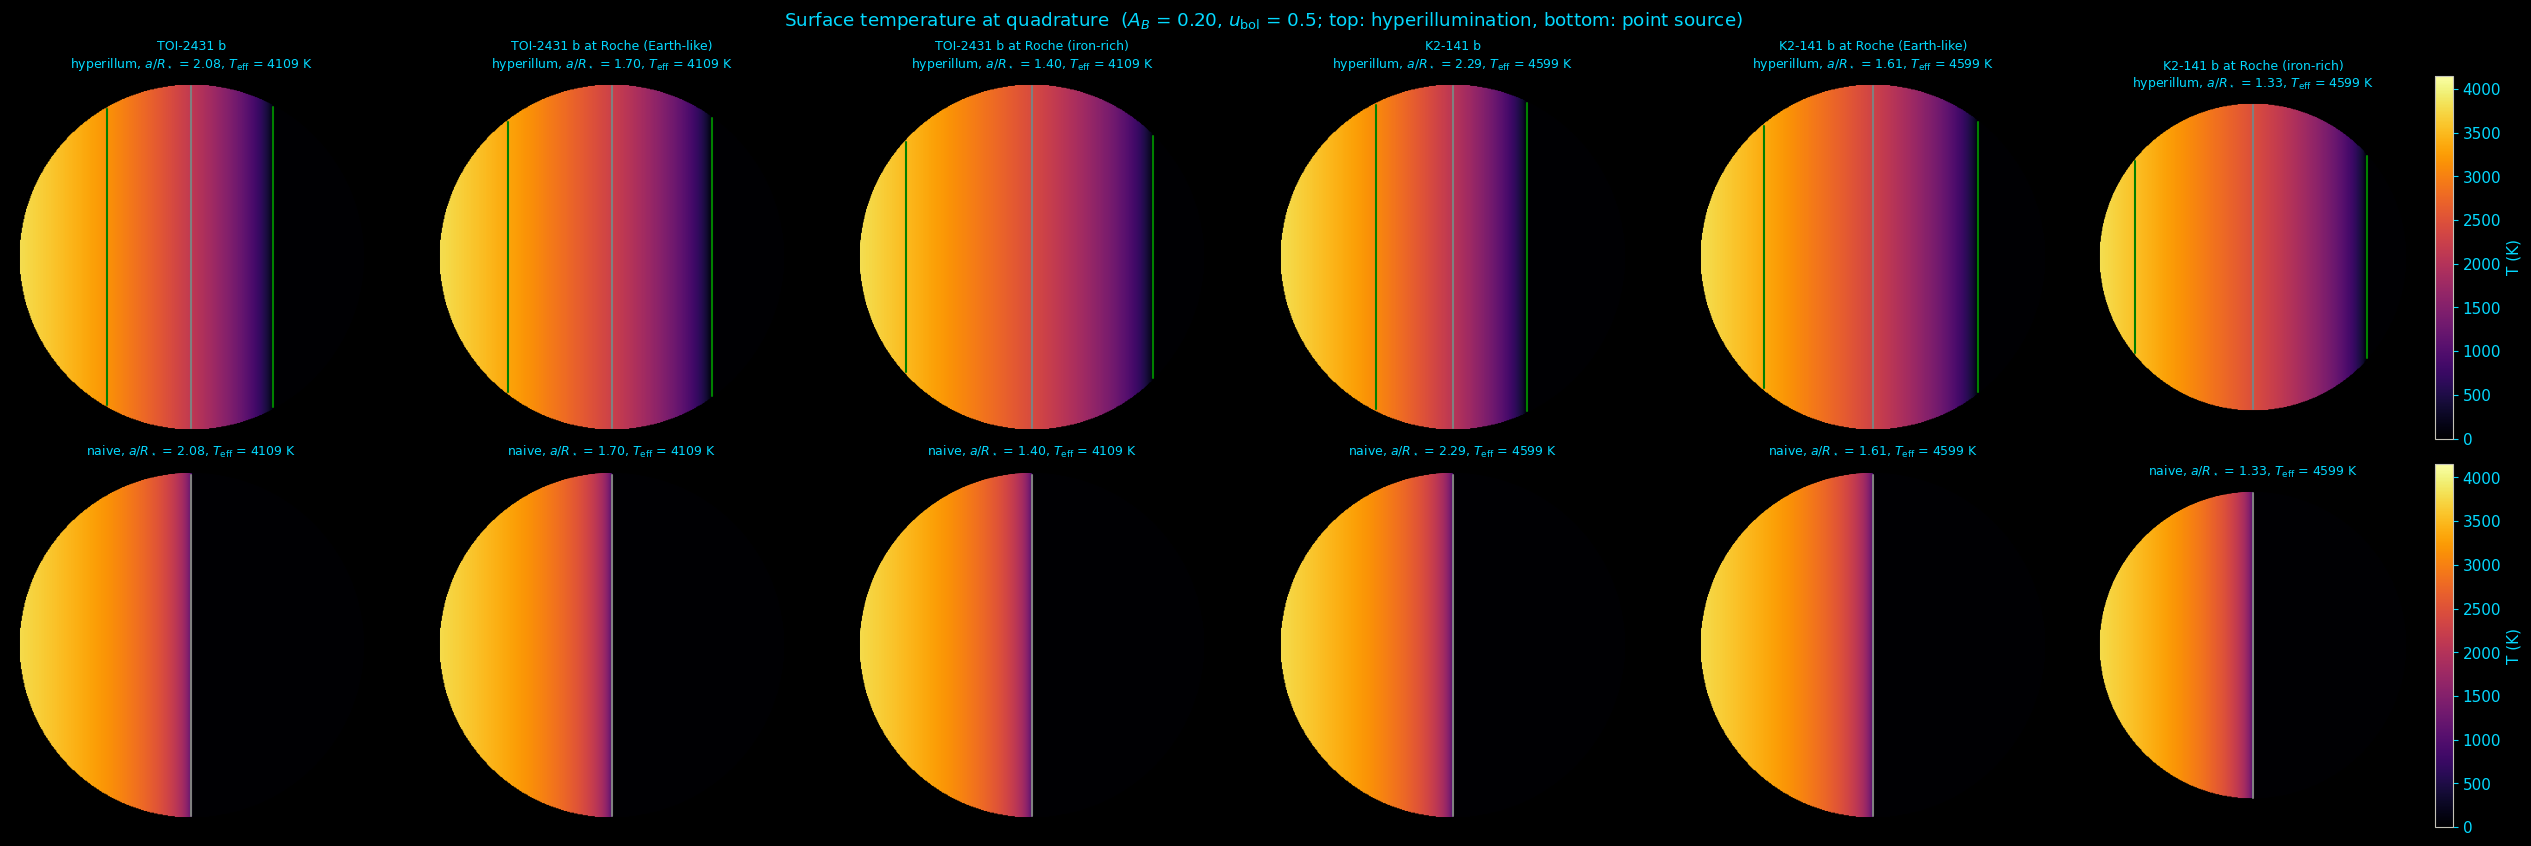

In [7]:
fig, axs = plot_model_insolmaps(edge, phase=0.25, u_bol=u_bol, A_B=A_B_true, theme="black", title=rf"Surface temperature at quadrature  ($A_B$ = {A_B_true:.2f}, $u_{{\rm bol}}$ = {u_bol:g}; top: hyperillumination, bottom: point source)")
plt.show()

### 3.2 Retrievals

Every planet fitted at its own geometry: the retrieved $A_B$ of both fits with Fisher bars (as in `03_bias_maps.ipynb` §2.2), and the false-positive test per planet (`plot_planet_false_F_bars`): $\sqrt{\Delta\chi^2_F}$ against `z_false`, with the fitted $F$, the nightside temperature and the critical noise under the axis.

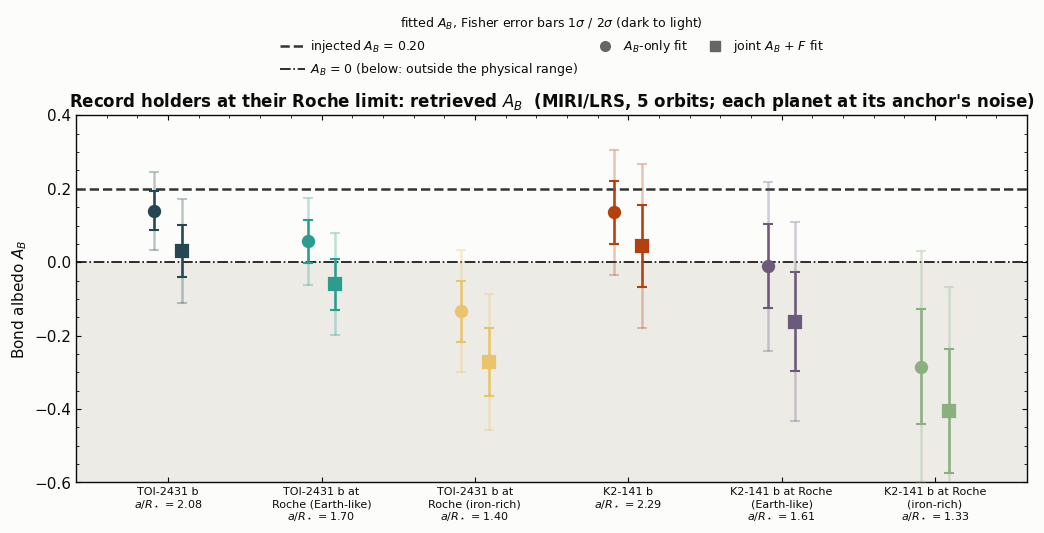

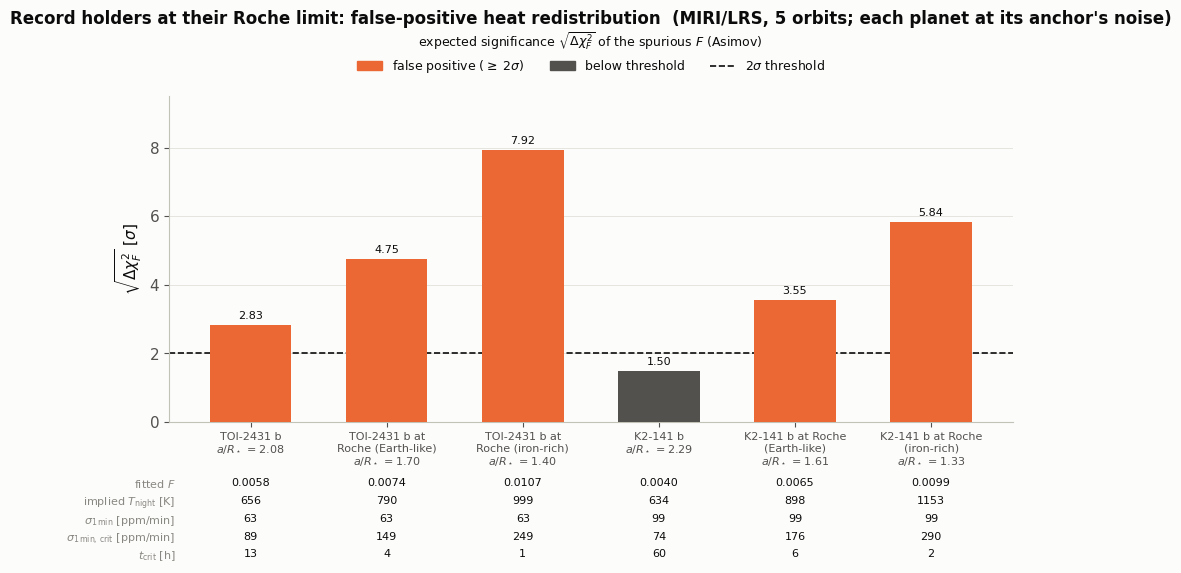

                            name  a_rs  T_eff  A_B_fit  sigma_A_B  bias_sigma          verdict  A_B_fit_J    F_fit   z_F
   K2-141 b at Roche (iron-rich) 1.327   4599  -0.2842     0.1571       3.082 needs hyperillum    -0.4055 0.009896 5.843
 TOI-2431 b at Roche (iron-rich) 1.398   4109  -0.1329    0.08312       4.006 needs hyperillum    -0.2717  0.01075  7.92
  K2-141 b at Roche (Earth-like)  1.61   4599 -0.01069     0.1152       1.828 needs hyperillum    -0.1618  0.00649 3.548
TOI-2431 b at Roche (Earth-like) 1.696   4109  0.05662    0.05948       2.411 needs hyperillum   -0.05947 0.007435 4.748
                      TOI-2431 b  2.08   4109   0.1402    0.05308       1.126 needs hyperillum    0.03086 0.005813 2.831
                        K2-141 b 2.292   4599   0.1363    0.08532       0.747         naive OK    0.04388 0.003967 1.497
fitted A_B < 0: A_B-only K2-141 b at Roche (iron-rich), TOI-2431 b at Roche (iron-rich), K2-141 b at Roche (Earth-like);  joint K2-141 b at Roche (iron-r

In [8]:
title_tail = f"({instrument}, {cfg.n_orbits} orbits; each planet at its anchor's noise)"

tab_case = planet_bias_table(cfg, A_B_true, edge, sigma_case, AGG=AGG, **kw)                  # A_B-only fit
tab_case_J = planet_bias_table(cfg, A_B_true, edge, sigma_case, redist=True, AGG=AGG, **kw)   # joint A_B + F fit
fig, ax = plot_planet_retrievals({"$A_B$-only fit": tab_case, "joint $A_B$ + $F$ fit": tab_case_J}, planets=list(edge), title=f"Reference planets at their Roche limit: retrieved $A_B$  {title_tail}")
plt.show()

z_false = 2.   # the false positive's significance [sigma] the verdict refers to
tab_false = planet_false_F_table(cfg, A_B_true, edge, sigma_case, z=z_false, AGG=AGG, **kw)
fig, ax = plot_planet_false_F_bars(tab_false, planets=list(edge), title=f"Reference planets at their Roche limit: false-positive heat redistribution  {title_tail}")
plt.show()

summary = tab_case[["name", "a_rs", "T_eff", "A_B_fit", "sigma_A_B", "bias_sigma", "verdict"]].merge(tab_case_J[["name", "A_B_fit", "F_fit"]].rename(columns={"A_B_fit": "A_B_fit_J"}), on="name").merge(tab_false[["name", "z_F"]], on="name")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
below = lambda t: ", ".join(t.loc[t["A_B_fit"] < 0., "name"]) or "none"   # fits below the physical floor (A_B_FIT_BOUNDS allows them)
print("fitted A_B < 0: A_B-only " + below(tab_case) + ";  joint " + below(tab_case_J))
print("railed: A_B-only " + (", ".join(railed_names(tab_case, A_B_true)) or "none") + ";  joint " + (", ".join(railed_names(tab_case_J, A_B_true)) or "none"))